In [1]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.datasets import load_diabetes

In [3]:
dataset = load_diabetes()

df = pd.DataFrame(dataset.data, columns=dataset.feature_names)


df['target'] = dataset.target


df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [4]:
df.tail()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0
441,-0.045472,-0.044642,-0.073030,-0.081413,0.083740,0.027809,0.173816,-0.039493,-0.004222,0.003064,57.0


In [5]:
df.shape

(442, 11)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [7]:
# Data Preprocessing

df.isnull().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.target.value_counts()

target
200.0    6
72.0     6
90.0     5
71.0     5
178.0    5
        ..
146.0    1
212.0    1
120.0    1
183.0    1
57.0     1
Name: count, Length: 214, dtype: int64

In [11]:
df.target=df.target.astype('int64')

<Axes: >

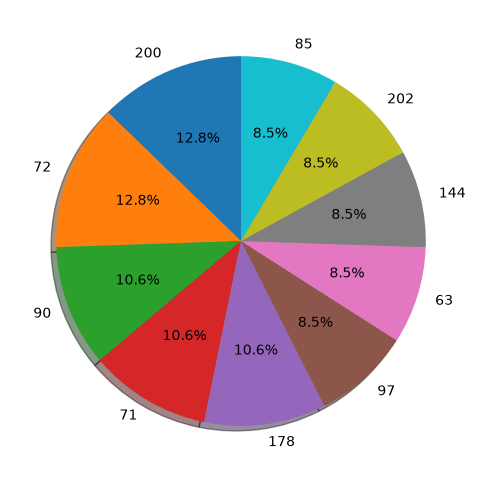

In [14]:
df.target.value_counts()[:10].plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6), shadow=True, startangle=90)

<Axes: ylabel='Density'>

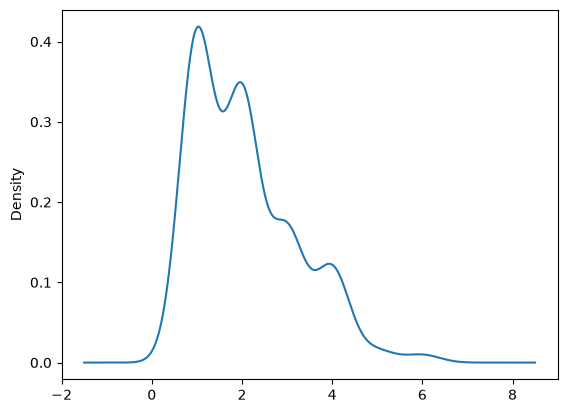

In [15]:
df.target.value_counts().plot(kind='kde')

<Axes: ylabel='Density'>

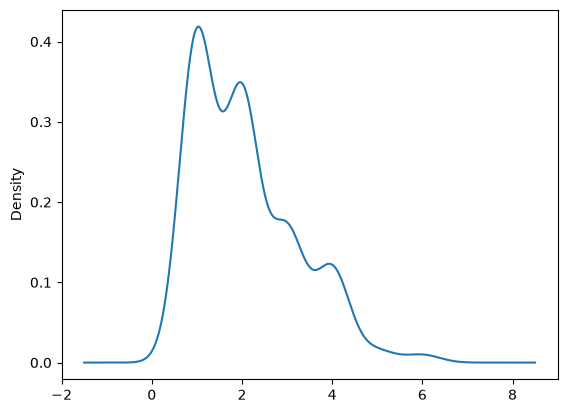

In [16]:
# apply log transformation to the target variable to reduce skewness

df['target'] = np.log(df['target'])

df.target.value_counts().plot(kind='kde')


In [1]:
# feature engineering

# feature selection

from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)


In [19]:
df.head(1)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.05068,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,5.01728


In [18]:
plot_numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [20]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target']])

,variables,VIF
0,age,1.217307
1,sex,1.278071
2,bmi,1.509437
3,bp,1.459428
4,s1,59.202510
5,s2,39.193370
6,s3,15.402156
7,s4,8.890986
8,s5,10.075967
9,s6,1.484623


In [21]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i!="s1"]])

,variables,VIF
0,age,1.216892
1,sex,1.275049
2,bmi,1.502320
3,bp,1.457413
4,s2,2.926535
5,s3,3.736890
6,s4,7.818670
7,s5,2.172865
8,s6,1.484410


In [22]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i!="s1" and i!="s4"]])

,variables,VIF
0,age,1.216284
1,sex,1.269207
2,bmi,1.498559
3,bp,1.447358
4,s2,1.180838
5,s3,1.473827
6,s5,1.641090
7,s6,1.476913


In [23]:
df.drop(columns=['s1', 's4'], inplace=True)

In [24]:
df.head(1)

,age,sex,bmi,bp,s2,s3,s5,s6,target
0,0.038076,0.05068,0.061696,0.021872,-0.034821,-0.043401,0.019907,-0.017646,5.01728


In [ ]:
# creating dependent and independent variables


X = df.drop(columns=['target'])

y = df['target']

In [26]:
# spliting the dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=117)

In [27]:
# feature scaling

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()


X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


In [34]:
from sklearn.neighbors import KNeighborsRegressor

knn=KNeighborsRegressor(n_neighbors=7)

knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [35]:
# model prediction

y_pred=knn.predict(X_test)


print("actual_values",y_test[:10])

print("predict_value",y_pred[:10])

actual_values 306    3.784190
9      5.736572
425    5.023881
411    4.912655
435    4.158883
362    5.771441
138    5.817111
181    4.158883
41     4.007333
409    5.198497
Name: target, dtype: float64
predict_value [4.67316492 5.14739258 4.47249005 4.6072135  4.88901644 5.52611745
 5.64742306 4.43072933 4.47611171 5.06326961]


In [37]:
# metrics

from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score



mae=mean_absolute_error(y_test,y_pred)

mse=mean_squared_error(y_test,y_pred)

rmse=np.sqrt(mse)


r2=r2_score(y_test,y_pred)


In [38]:
print("mae",mae)

print("mse",mse)

print("rmse",rmse)


print("r2",r2)

mae 0.3777672922270456
mse 0.21793627396130763
rmse 0.4668364531196205
r2 0.3684606875256332
